# Лабораторная работа №2: Непараметрические методы регрессии (kNN и Ядерная регрессия Надарая-Ватсона)
### Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import mean_absolute_error,r2_score


### Загрузка данных и разведочный анализ (EDA)

In [2]:
df = pd.read_csv("used_car_price_dataset_extended.csv")

print(f"Размеры таблицы: {df.shape[0]} автомобилей и {df.shape[1]} параметров")
df.head(3)
fuel_impact = df.groupby("fuel_type")["price_usd"].median()
print("\nМедианная стоимость ($) в зависимости от типа топлива: \n", fuel_impact)
df.head(3)



Размеры таблицы: 10000 автомобилей и 12 параметров

Медианная стоимость ($) в зависимости от типа топлива: 
 fuel_type
Diesel      6754.22
Electric    9684.73
Petrol      6673.44
Name: price_usd, dtype: float64


,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid
0,2001,8.17,4000,Petrol,4,8587.64,Chevrolet,Manual,White,NaN,0,No
1,2014,17.59,1500,Petrol,4,5943.50,Honda,Manual,Black,NaN,0,Yes
2,2023,18.09,2500,Diesel,5,9273.58,BMW,Automatic,Black,Full,1,Yes


> **Вывод:** Датасет успешно загружен (10 000 строк и 12 признаков). Медианная стоимость электромобилей ($9 685) существенно превышает стоимость дизельных ($6 754) и бензиновых ($6 673) автомобилей, что показывает влияние типа топлива на рыночную цену.

### Кодирование категориальных признаков и масштабирование

In [3]:
df = pd.get_dummies(df, drop_first=True)
df.head(3)

X = df.drop('price_usd', axis=1)
Y = df['price_usd']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.8, random_state=42)

number_cols = ['make_year', 'mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported']
scaler = StandardScaler()
X_train[number_cols] = scaler.fit_transform(X_train[number_cols])
X_test[number_cols] = scaler.transform(X_test[number_cols])

X_train.head(3)



,make_year,mileage_kmpl,engine_cc,owner_count,accidents_reported,fuel_type_Electric,fuel_type_Petrol,brand_Chevrolet,brand_Ford,brand_Honda,...,brand_Toyota,brand_Volkswagen,transmission_Manual,color_Blue,color_Gray,color_Red,color_Silver,color_White,service_history_Partial,insurance_valid_Yes
9254,-0.860884,-1.644253,-0.379682,-0.705460,-0.703197,False,False,False,False,False,...,False,False,True,False,False,False,True,False,True,False
1561,-0.622453,-0.368146,-0.612288,-0.000793,-0.703197,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
1670,-0.503238,-1.482746,2.101455,-0.705460,-0.703197,False,False,False,True,False,...,False,False,True,False,True,False,False,False,False,False


> **Вывод:** Выполнено кодирование категориальных признаков с drop_first=True. Данные разбиты на обучающую (80%) и тестовую (20%) выборки, а числовые признаки отмасштабированы с помощью StandardScaler.

### Поиск оптимального числа соседей (k)

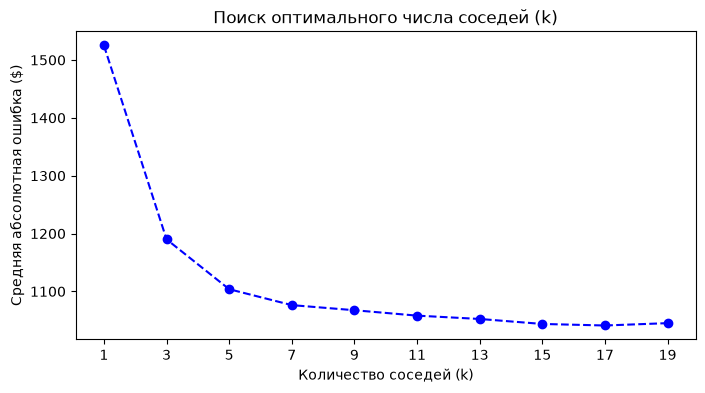

In [4]:
errors = []
k_values = range(1, 20, 2)

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, Y_train)
    y_pred = knn.predict(X_test)
    errors.append(mean_absolute_error(Y_test, y_pred))

plt.figure(figsize=(8,4))
plt.plot(k_values, errors, marker="o", linestyle="dashed", color="blue")
plt.title("Поиск оптимального числа соседей (k)")
plt.xlabel("Количество соседей (k)")
plt.ylabel("Средняя абсолютная ошибка ($)")
plt.xticks(k_values)
plt.show()



> **Вывод:** для обучения модели число соседей k=5 является оптимальным

### Исследование метрик расстояния Минковского

In [5]:
best_k = 5
#Обучаем модель с Евклидовой метрикой p=2
knn_euclidean = KNeighborsRegressor(n_neighbors=best_k, p=2)
knn_euclidean.fit(X_train, Y_train)
y_pred_euc = knn_euclidean.predict(X_test)

#Обучаем модель с Манхэттенской метрикой p=1
knn_manhattan = KNeighborsRegressor(n_neighbors=best_k, p=1)
knn_manhattan.fit(X_train, Y_train)
y_pred_man = knn_manhattan.predict(X_test)

print("=== Сравнение метрик расстояния ===")
print(f"Евклидово расстояние (p=2): MAE = ${mean_absolute_error(Y_test, y_pred_euc):,.2f} | R2 = {r2_score(Y_test, y_pred_euc):,.2f}")
print(f"Манхэттенское расстояние (p=1): MAE = ${mean_absolute_error(Y_test, y_pred_man):,.2f} | R2 = {r2_score(Y_test, y_pred_man):,.2f}")



=== Сравнение метрик расстояния ===
Евклидово расстояние (p=2): MAE = $1,103.79 | R2 = 0.75
Манхэттенское расстояние (p=1): MAE = $1,156.94 | R2 = 0.73


> **Вывод:** Евклидово расстояние ($p=2$) превзошло Манхэттенское ($p=1$). R2 больше на 0.2

### Регрессия Надарая-Ватсона

In [6]:
gamma_values = np.logspace(-2,1, 30)

best_gamma = 0
best_r2 = -float("inf")
best_mae = float("inf")

for g in gamma_values:
    weights = rbf_kernel(X_test, X_train, gamma=g)
    weights_normalized = weights / weights.sum(axis=1, keepdims=True)

    y_pred_nw = np.dot(weights_normalized, Y_train.values)
    r2 = r2_score(Y_test, y_pred_nw)
    mae = mean_absolute_error(Y_test, y_pred_nw)

    if r2 > best_r2:
        best_r2 = r2
        best_mae = mae
        best_gamma = g

print("=== Итоги оптимизации ядерной регрессии ===")
print(f"Оптимальный gamma: {best_gamma:.2f}")
print(f"Лучшее R2: {best_r2:.2f}")
print(f"Лучшее MAE: ${best_mae:.2f}")



=== Итоги оптимизации ядерной регрессии ===
Оптимальный gamma: 1.49
Лучшее R2: 0.77
Лучшее MAE: $1063.84


> **Вывод:** Оптимальная ширина окна Гауссовского ядра составила  1.49. Ядерная регрессия Надарая-Ватсона показала высокое качество (R2 = 0.77, MAE = 1 063.84)

### Визуализация и финальный бизнес-вывод

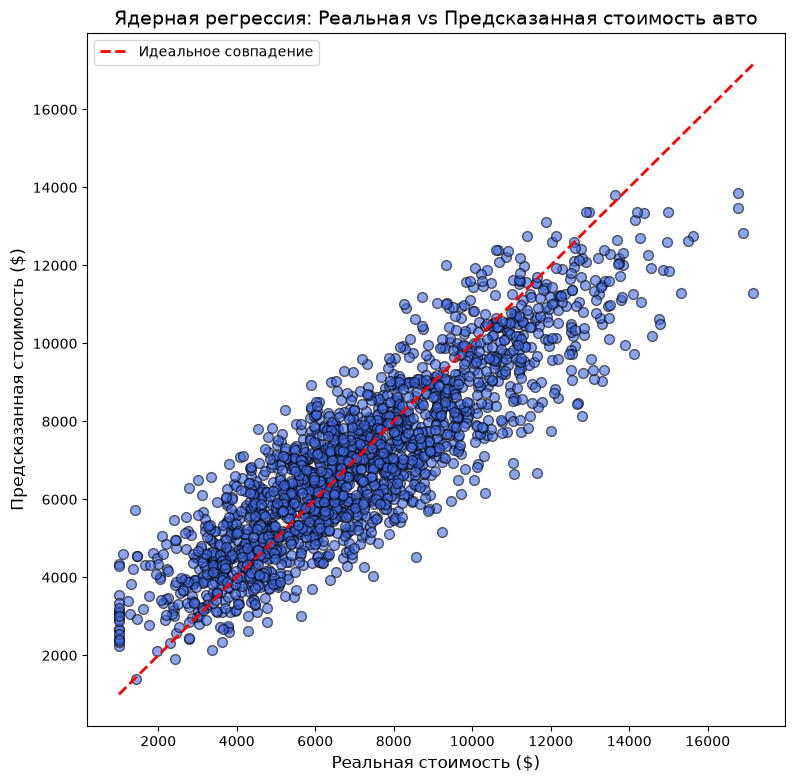

In [8]:
plt.figure(figsize=(9,9))

plt.scatter(Y_test, y_pred_euc, alpha=0.6, color="royalblue", edgecolor="k", s=50)

max_val = max(Y_test.max(), y_pred_euc.max())
min_val = min(Y_test.min(), y_pred_euc.min())

plt.plot(
    [min_val, max_val], [min_val, max_val], "r--", lw=2, label="Идеальное совпадение"
)

plt.title("Ядерная регрессия: Реальная vs Предсказанная стоимость авто", fontsize=14)
plt.xlabel("Реальная стоимость ($)", fontsize=12)
plt.ylabel("Предсказанная стоимость ($)", fontsize=12)
plt.legend()
plt.show()



> **Финальный вывод:** Автодилеры могут использовать данную модель для автоматического анализа стоимости трейд-ин авто, быстрой первичной оценки выкупа и выявления аномалий цен в объявлениях без участия оценщика. Но как инструмент для точной оценки, эта модель не подойдет из-за большого разброса